- Dataset Link: https://www.kaggle.com/datasets/mohankrishnathalla/diabetes-health-indicators-dataset
- File Link: https://drive.google.com/file/d/1abEZ8AvE_Qz1iOJOfWptEeCWjjHez0eX/view?usp=sharing
- File ID: `1abEZ8AvE_Qz1iOJOfWptEeCWjjHez0eX`

## Dataset Load

In [1]:
import os
!pip install -U gdown -q

# --- Dataset Loading Choice ---
# Set to 'gdown' to use gdown for downloading the file.
# Set to 'drive_mount' to mount Google Drive and access the file.
# Make sure the file_path_after_mount below is correct if using 'drive_mount'.
DATA_LOAD_METHOD = 'gdown' #

# Variable to store the final path to the dataset
dataset_path = None

if DATA_LOAD_METHOD == 'gdown':
    folder_path = "/content/dataset"
    file_name = "diabetes_dataset.csv"
    file_id = "1abEZ8AvE_Qz1iOJOfWptEeCWjjHez0eX"
    try:
        if not os.path.exists(folder_path):
            os.makedirs(folder_path)
            print(f"Folder '{folder_path}' created.")
        else:
            print(f"Folder '{folder_path}' already exists.")
        dataset_path = f"{folder_path}/{file_name}"
        print(f"- File ID: {file_id}")
        print(f"- Folder: {folder_path}")
        !gdown "{file_id}" --output "{dataset_path}"
        print("Dataset loaded successfully using gdown.")
    except Exception as e:
        print(f"An error occurred during gdown: {e}")

elif DATA_LOAD_METHOD == 'drive_mount':
    # --- Configuration for 'drive_mount' method ---
    # IMPORTANT: Update this path if you choose 'drive_mount' and the file is in a different location.
    file_path_after_mount = "/content/drive/MyDrive/diabetes_dataset.csv"
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        print("Google Drive mounted.")

        # If not copying, the dataset_path is directly the mounted file path
        if os.path.exists(file_path_after_mount):
            dataset_path = file_path_after_mount
            print(f"Using dataset directly from Google Drive: '{dataset_path}'.")
        else:
            print(f"Error: File not found in Google Drive at '{file_path_after_mount}'. Please update the 'file_path_after_mount' variable.")
    except Exception as e:
        print(f"An error occurred during Drive Mount: {e}")

else:
    print("Invalid DATA_LOAD_METHOD. Please choose 'gdown' or 'drive_mount'.")

# Ensure dataset_path is set before proceeding
if dataset_path:
    print(f"Final dataset path set to: {dataset_path}")
else:
    print("Error: dataset_path was not set. Please check DATA_LOAD_METHOD and file paths.")


Folder '/content/dataset' created.
- File ID: 1abEZ8AvE_Qz1iOJOfWptEeCWjjHez0eX
- Folder: /content/dataset
Downloading...
From: https://drive.google.com/uc?id=1abEZ8AvE_Qz1iOJOfWptEeCWjjHez0eX
To: /content/dataset/diabetes_dataset.csv
100% 14.4M/14.4M [00:00<00:00, 63.0MB/s]
Dataset loaded successfully using gdown.
Final dataset path set to: /content/dataset/diabetes_dataset.csv


In [2]:
import pandas as pd

# Use the dataset_path variable set in the previous cell
if 'dataset_path' in globals() and dataset_path is not None:
    data_raw = pd.read_csv(dataset_path)
else:
    # Fallback or error handling if dataset_path is not properly set
    print("Error: dataset_path variable not found or is None. Please ensure previous cell is run correctly.")
    # As a fallback, you might want to provide a default path or raise an error.
    # For this example, we'll revert to the original hardcoded path if dataset_path is not available.
    data_raw = pd.read_csv('/content/dataset/diabetes_dataset.csv') # Fallback

# Set pandas options to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
#data_raw.value_counts(normalize=True)


## EDA

In [3]:
## dataset summary

import pandas as pd

# Create an empty list to store column information
column_info_list = []

total_rows = len(data_raw)

# Iterate through each column in the DataFrame
for col in data_raw.columns:
    # Get data type
    data_type = data_raw[col].dtype

    # Calculate missing count
    missing_count = data_raw[col].isnull().sum()

    # Get number of unique values
    unique_values = data_raw[col].nunique()

    # Determine column type (simple heuristic based on dtype)
    if pd.api.types.is_numeric_dtype(data_raw[col]):
        column_type = 'Numerical'
        # Get min and max for numerical columns
        min_value = data_raw[col].min()
        max_value = data_raw[col].max()
    else:
        column_type = 'Categorical'
        # Set min and max to "-" for non-numerical columns
        min_value = "-"
        max_value = "-"

    # Append information to the list
    column_info_list.append({
        'Column Name': col,
        'dataType': data_type,
        'missingCount': missing_count,
        'uniqueValue': unique_values,
        'minValue': min_value,
        'maxValue': max_value,
        'columnType': column_type
    })

# Create a DataFrame from the list of dictionaries
column_summary_df = pd.DataFrame(column_info_list)

# Display the summary table
print(f"Dataset Shape: {data_raw.shape}")
print("Dataset Head:")
display(data_raw.head(20))
print("Dataset tail:")
display(data_raw.tail(1))
print("Dataset Column Summary:")
display(column_summary_df)

# Check for duplicate rows
duplicate_rows_count = data_raw.duplicated().sum()
duplicate_rows_percentage = (duplicate_rows_count / len(data_raw)) * 100

# Create a separate DataFrame for duplicate rows summary
duplicate_summary_data = {
    'Metric': [
        'Total Duplicate Rows',
        'Percentage of Duplicate Rows'
    ],
    'Value': [
        duplicate_rows_count,
        f"{duplicate_rows_percentage:.2f}%"
    ]
}
duplicate_summary_df = pd.DataFrame(duplicate_summary_data)

print("\nDuplicate Rows Summary:")
display(duplicate_summary_df)

# Count numerical and categorical features
numerical_count = column_summary_df[column_summary_df['columnType'] == 'Numerical'].shape[0]
categorical_count = column_summary_df[column_summary_df['columnType'] == 'Categorical'].shape[0]

# Create a separate DataFrame for column type counts summary
column_type_summary_data = {
    'Metric': [
        'Number of Numerical Features',
        'Number of Categorical Features'
    ],
    'Value': [
        numerical_count,
        categorical_count
    ]
}
column_type_summary_df = pd.DataFrame(column_type_summary_data)

print("\nColumn Type Counts Summary:")
display(column_type_summary_df)

Dataset Shape: (100000, 31)
Dataset Head:


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,waist_to_hip_ratio,systolic_bp,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,7.9,7.9,0,0,0,30.5,0.89,134,78,68,239,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,6.5,8.7,0,0,0,23.1,0.80,129,76,67,116,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,10.0,8.1,1,0,0,22.2,0.81,115,73,74,213,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,6.6,5.2,0,0,0,26.8,0.88,120,93,68,171,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,7.4,5.0,0,0,0,21.2,0.78,92,67,67,210,52,125,160,137,184,12.74,7.20,23.5,Type 2,1
5,46,Female,White,Highschool,Upper-Middle,Employed,Never,2,124,9.0,6.2,5.4,0,0,0,26.1,0.85,95,81,57,218,61,119,179,100,133,8.77,6.03,23.5,Pre-Diabetes,0
6,75,Female,White,Graduate,Upper-Middle,Retired,Never,0,53,9.2,7.8,8.0,0,1,0,25.1,0.88,129,77,81,238,46,161,155,101,100,10.14,5.24,36.1,Pre-Diabetes,0
7,62,Male,White,Postgraduate,Middle,Unemployed,Current,1,75,4.1,9.0,12.9,0,1,1,23.9,0.86,128,83,76,241,49,159,120,110,189,8.96,7.04,34.2,Type 2,1
8,42,Male,Black,Highschool,Lower-Middle,Employed,Current,1,114,6.7,8.5,8.5,0,0,1,24.7,0.84,103,71,72,187,33,132,98,116,172,5.70,6.90,26.7,Type 2,1
9,59,Female,White,Graduate,Middle,Employed,Current,3,86,8.2,5.3,7.4,0,0,0,26.7,0.81,124,81,70,188,52,103,104,76,109,4.49,4.99,30.0,No Diabetes,0


Dataset tail:


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,waist_to_hip_ratio,systolic_bp,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
99999,52,Female,White,Postgraduate,Middle,Employed,Never,1,248,2.7,5.4,5.5,0,0,0,30.3,1.0,109,77,55,238,31,183,87,91,142,15.93,5.73,27.9,Pre-Diabetes,0


Dataset Column Summary:


,Column Name,dataType,missingCount,uniqueValue,minValue,maxValue,columnType
0,age,int64,0,73,18,90,Numerical
1,gender,object,0,3,-,-,Categorical
2,ethnicity,object,0,5,-,-,Categorical
3,education_level,object,0,4,-,-,Categorical
4,income_level,object,0,5,-,-,Categorical
5,employment_status,object,0,4,-,-,Categorical
6,smoking_status,object,0,3,-,-,Categorical
7,alcohol_consumption_per_week,int64,0,11,0,10,Numerical
8,physical_activity_minutes_per_week,int64,0,620,0,833,Numerical
9,diet_score,float64,0,101,0.0,10.0,Numerical



Duplicate Rows Summary:


,Metric,Value
0,Total Duplicate Rows,0
1,Percentage of Duplicate Rows,0.00%



Column Type Counts Summary:


,Metric,Value
0,Number of Numerical Features,24
1,Number of Categorical Features,7


Boxplots for Numerical Columns (Outlier Detection):


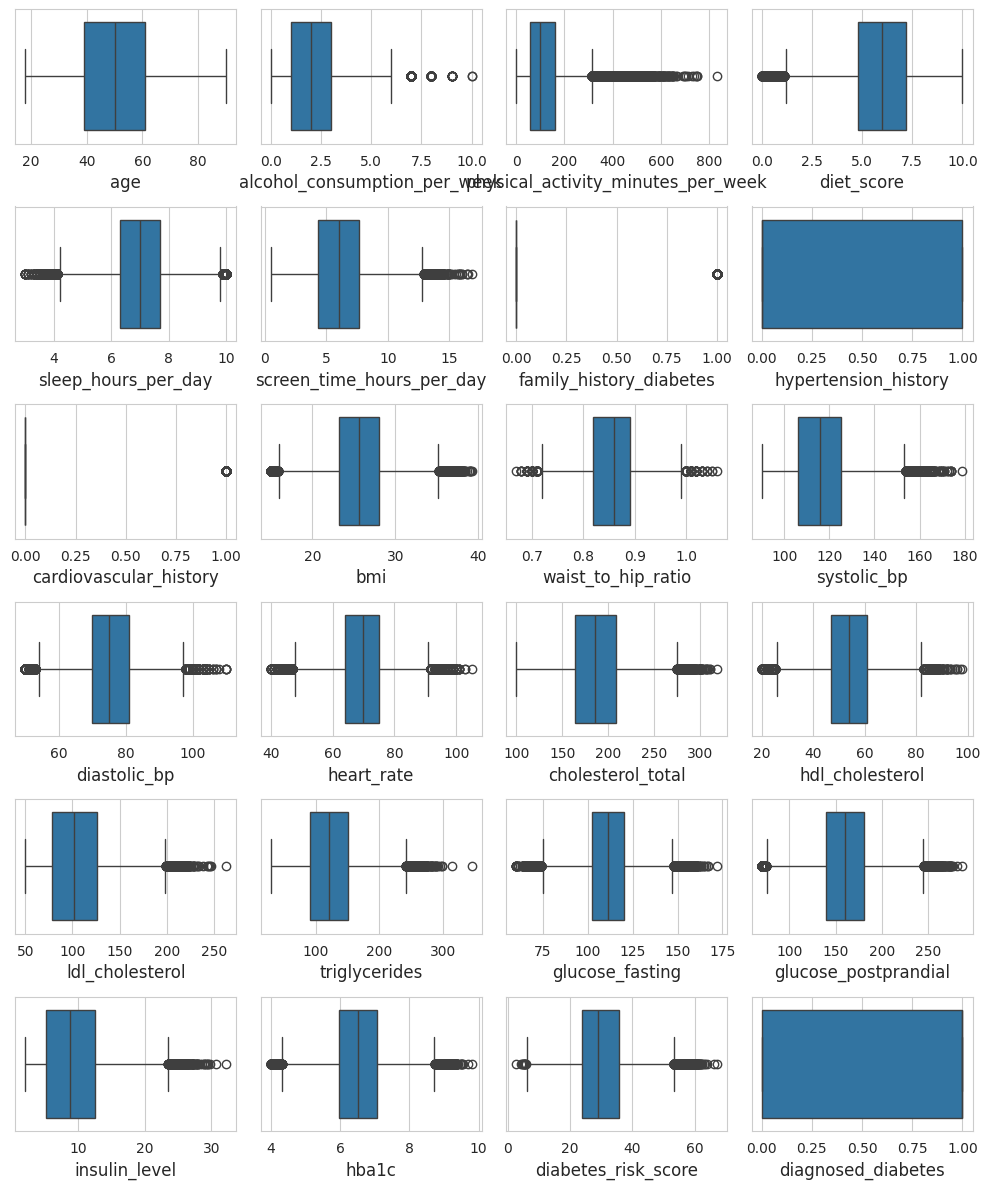


Distributions of Numerical Columns:


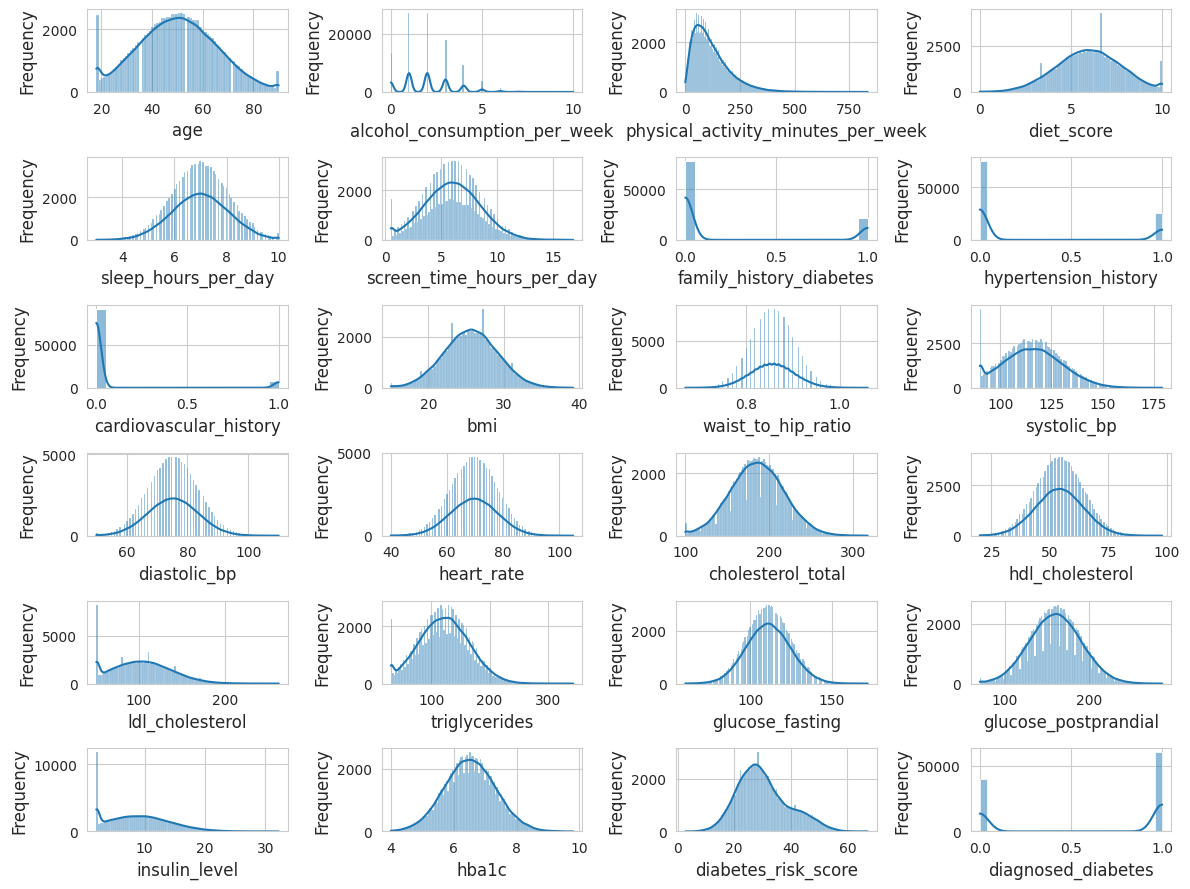


Correlation Heatmap:


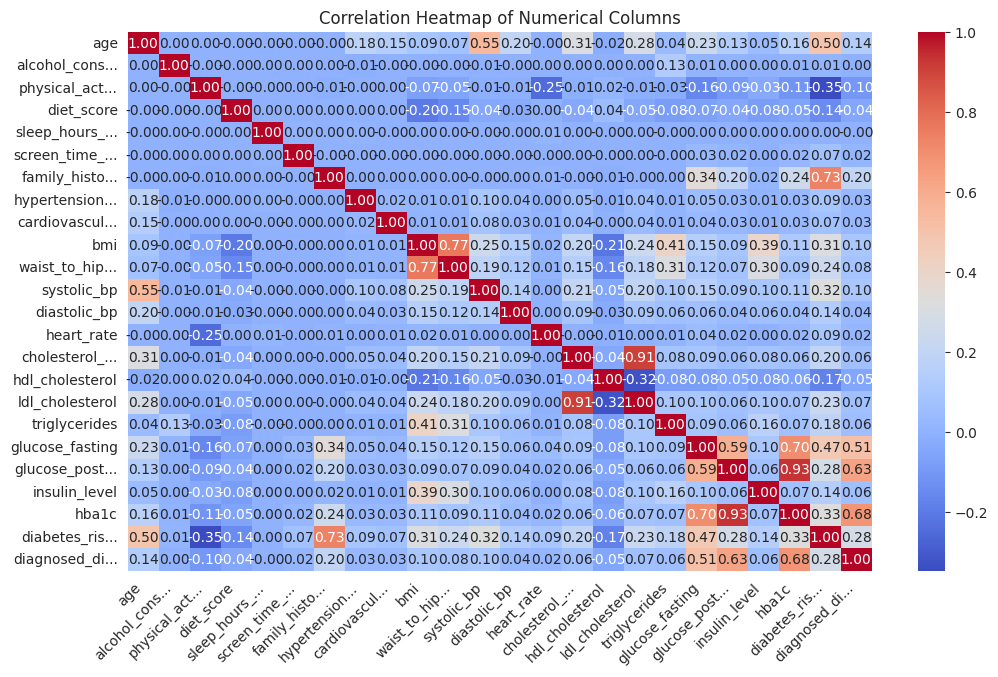

In [4]:
## numerical features summary

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import json
import datetime
import numpy as np

# Set plot style and font sizes
sns.set_style("whitegrid")
plt.rcParams.update({
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.labelsize': 12
})

# Select only numerical columns
numerical_cols = data_raw.select_dtypes(include=['int64', 'float64']).columns

# --- Boxplots for Numerical Columns (Outlier Detection) in one figure ---
print("Boxplots for Numerical Columns (Outlier Detection):")

# Determine the number of rows and columns for the subplot grid
n_cols = 4  # You can adjust the number of columns
n_rows = (len(numerical_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 2.5, n_rows * 2))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, col in enumerate(numerical_cols):
    sns.boxplot(x=data_raw[col], ax=axes[i])
    #axes[i].set_title(col)
    axes[i].set_xlabel(col)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# --- Distributions of Numerical Columns in one figure ---
print("\nDistributions of Numerical Columns:")

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3, n_rows * 1.5))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, col in enumerate(numerical_cols):
    sns.histplot(data_raw[col], kde=True, ax=axes[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# --- Correlation Heatmap (remains a single figure) ---
print("\nCorrelation Heatmap:")
# Select only numerical columns for correlation heatmap
correlation_cols = data_raw.select_dtypes(include=['int64', 'float64'])

# Function to truncate labels
def truncate_label(label, max_len=15):
    if len(label) > max_len:
        return label[:max_len-3] + "..."
    return label

# Apply truncation to column names
truncated_labels = [truncate_label(col) for col in correlation_cols.columns]

plt.figure(figsize=(12, 7))
ax = sns.heatmap(
    correlation_cols.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
)
plt.title('Correlation Heatmap of Numerical Columns')

# Set truncated labels and rotation for x-axis
ax.set_xticklabels(truncated_labels, rotation=45, ha='right')
# Set truncated labels and rotation for y-axis
ax.set_yticklabels(truncated_labels, rotation=0)

plt.show()

# --- Refactored Export Visualization Data to JSON Function ---
def export_numerical_viz_data_to_json(numerical_cols, data_raw, correlation_cols, do_export=True):
    if not do_export:
        print("Exporting visualization data is disabled.")
        return

    print("\nExporting visualization data to JSON...")

    # Data for boxplots and histograms
    numerical_features_data = {}
    for col in numerical_cols:
        # Convert numpy types to native Python types for JSON serialization
        numerical_features_data[col] = data_raw[col].replace({np.nan: None}).tolist() # Handle NaN by converting to None

    # Data for correlation matrix
    correlation_matrix_df = correlation_cols.corr()
    correlation_matrix_data = {
        "columns": correlation_matrix_df.columns.tolist(),
        "index": correlation_matrix_df.index.tolist(),
        "data": correlation_matrix_df.replace({np.nan: None}).values.tolist() # Handle NaN
    }

    export_viz_data = {
        "metadata": {
            "export_time": datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "description": "Data used for numerical feature visualizations (boxplots, histograms, correlation heatmap)"
        },
        "numerical_features_raw_data": numerical_features_data,
        "correlation_matrix_data": correlation_matrix_data
    }

    # Define a custom JSON encoder for NumPy types if needed, or convert proactively
    class CustomNumpyEncoder(json.JSONEncoder):
        def default(self, obj):
            if isinstance(obj, (np.integer, np.floating)):
                return obj.item()
            elif isinstance(obj, np.ndarray):
                return obj.tolist()
            return json.JSONEncoder.default(self, obj)

    timestamp_str = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
    filename = f"numerical_viz_data_{timestamp_str}.json"

    try:
        with open(filename, 'w') as f:
            json.dump(export_viz_data, f, indent=4, cls=CustomNumpyEncoder)
        print(f"Successfully exported visualization data to {filename}")
        # Optionally, auto-download in Colab
        try:
            from google.colab import files
            files.download(filename)
        except ImportError:
            pass
    except Exception as e:
        print(f"Error exporting visualization data: {e}")

# Call the new function to export data (set do_export=False to disable)
#export_numerical_viz_data_to_json(numerical_cols, data_raw, correlation_cols, do_export=True)


In [5]:
## categorical feature summary

import pandas as pd

print("\nSummary Table of Unique Value Counts for Categorical Columns:")

categorical_cols = data_raw.select_dtypes(include='object').columns

if len(categorical_cols) == 0:
    print("No categorical columns found.")
else:
    summary_rows = []
    for col in categorical_cols:
        # Get value counts for the current column
        value_counts_series = data_raw[col].value_counts()

        # Iterate through the unique values and their counts
        for value, count in value_counts_series.items():
            summary_rows.append({
                'Column Name': col,
                'Value': value,
                'Count': count
            })

    # Create a DataFrame from the collected rows
    summary_df_flat = pd.DataFrame(summary_rows)
    display(summary_df_flat)


Summary Table of Unique Value Counts for Categorical Columns:


,Column Name,Value,Count
0,gender,Female,50216
1,gender,Male,47771
2,gender,Other,2013
3,ethnicity,White,44997
4,ethnicity,Hispanic,20103
5,ethnicity,Black,17986
6,ethnicity,Asian,11865
7,ethnicity,Other,5049
8,education_level,Highschool,44891
9,education_level,Graduate,35037


In [6]:
print(data_raw.columns.tolist())

['age', 'gender', 'ethnicity', 'education_level', 'income_level', 'employment_status', 'smoking_status', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'ldl_cholesterol', 'triglycerides', 'glucose_fasting', 'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score', 'diabetes_stage', 'diagnosed_diabetes']


In [7]:
import pandas as pd

# --- 1. Proportion for the entire 'diabetes_stage' feature (from data_raw) ---
print("\n--- Proportions of 'diabetes_stage' in the original dataset (data_raw) ---")
original_stage_proportions = data_raw['diabetes_stage'].value_counts(normalize=True).reset_index()
original_stage_proportions.columns = ['Diabetes Stage', 'Proportion']
display(original_stage_proportions)

# --- 2. Proportion for the subset 'Type 2' and 'No Diabetes' ---
# Recreate the subset as it was before dropping the column in 'data_t2' creation
filtered_data_for_stage = data_raw[data_raw['diabetes_stage'].isin(['Type 2', 'No Diabetes'])].copy()

print("\n--- Proportions of 'diabetes_stage' subset (Type 2 and No Diabetes) ---")
subset_stage_proportions = filtered_data_for_stage['diabetes_stage'].value_counts(normalize=True).reset_index()
subset_stage_proportions.columns = ['Diabetes Stage', 'Proportion']
display(subset_stage_proportions)



--- Proportions of 'diabetes_stage' in the original dataset (data_raw) ---


,Diabetes Stage,Proportion
0,Type 2,0.59774
1,Pre-Diabetes,0.31845
2,No Diabetes,0.07981
3,Gestational,0.00278
4,Type 1,0.00122



--- Proportions of 'diabetes_stage' subset (Type 2 and No Diabetes) ---


,Diabetes Stage,Proportion
0,Type 2,0.882208
1,No Diabetes,0.117792


## Data Filtering

In [8]:
# data filtering
import pandas as pd

# Copy data_raw into data_t2
data_prep = data_raw.copy()

print("Original data_t2 shape (before filtering):")
print(data_prep.shape)

# Filter data_t2 by diabetes_stage and make an explicit copy
data_t2 = data_prep[data_prep['diabetes_stage'].isin(['Type 2', 'No Diabetes'])].copy()

data_t2.drop(columns=['diabetes_stage'], inplace=True)

# Reset index after filtering to ensure a contiguous index
data_t2.reset_index(drop=True, inplace=True)

print("\nFiltered data_t2 shape:")
print(data_t2.shape)
print("\nFiltered data_t2 head:")
display(data_t2.head(10))
print("\nFiltered data_t2 tail:")
display(data_t2.tail(10))

Original data_t2 shape (before filtering):
(100000, 31)

Filtered data_t2 shape:
(67755, 30)

Filtered data_t2 head:


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,waist_to_hip_ratio,systolic_bp,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,7.9,7.9,0,0,0,30.5,0.89,134,78,68,239,41,160,145,136,236,6.36,8.18,29.6,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,6.5,8.7,0,0,0,23.1,0.80,129,76,67,116,55,50,30,93,150,2.00,5.63,23.0,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,10.0,8.1,1,0,0,22.2,0.81,115,73,74,213,66,99,36,118,195,5.07,7.51,44.7,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,6.6,5.2,0,0,0,26.8,0.88,120,93,68,171,50,79,140,139,253,5.28,9.03,38.2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,7.4,5.0,0,0,0,21.2,0.78,92,67,67,210,52,125,160,137,184,12.74,7.20,23.5,1
5,62,Male,White,Postgraduate,Middle,Unemployed,Current,1,75,4.1,9.0,12.9,0,1,1,23.9,0.86,128,83,76,241,49,159,120,110,189,8.96,7.04,34.2,1
6,42,Male,Black,Highschool,Lower-Middle,Employed,Current,1,114,6.7,8.5,8.5,0,0,1,24.7,0.84,103,71,72,187,33,132,98,116,172,5.70,6.90,26.7,1
7,59,Female,White,Graduate,Middle,Employed,Current,3,86,8.2,5.3,7.4,0,0,0,26.7,0.81,124,81,70,188,52,103,104,76,109,4.49,4.99,30.0,0
8,43,Female,White,Highschool,Middle,Employed,Never,1,118,7.5,5.2,5.4,0,0,0,24.8,0.86,109,85,66,144,44,79,182,124,177,14.48,7.34,25.3,1
9,43,Female,White,Highschool,Middle,Employed,Former,1,167,7.2,6.9,5.1,0,1,0,22.3,0.76,119,69,66,163,59,61,49,117,183,12.93,7.40,18.5,1



Filtered data_t2 tail:


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,waist_to_hip_ratio,systolic_bp,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diagnosed_diabetes
67745,57,Male,White,Postgraduate,Middle,Employed,Former,1,50,3.6,8.7,4.2,0,1,0,25.6,0.84,121,83,65,192,44,124,170,106,184,3.36,7.22,33.7,1
67746,21,Other,Asian,Highschool,Lower-Middle,Retired,Current,2,98,3.9,7.6,5.2,0,0,0,20.9,0.77,91,70,71,190,52,112,153,99,181,9.26,7.00,18.5,1
67747,62,Female,White,Highschool,Low,Retired,Never,4,50,4.0,6.7,4.8,0,0,0,22.9,0.84,118,76,64,216,37,131,113,111,184,2.00,7.34,34.0,1
67748,41,Male,Hispanic,Postgraduate,High,Retired,Former,2,93,3.7,7.1,4.7,0,0,0,27.8,0.86,116,77,62,157,54,101,180,125,161,11.78,6.63,27.4,1
67749,60,Female,White,Highschool,Low,Retired,Never,1,243,6.6,4.8,4.7,0,0,0,26.3,0.87,128,88,61,151,52,90,109,117,175,8.48,6.84,23.9,1
67750,63,Female,White,Highschool,Middle,Unemployed,Never,4,65,4.0,6.8,9.8,0,0,0,30.6,0.88,125,86,75,203,66,97,224,138,191,10.75,7.23,37.0,1
67751,47,Female,White,Graduate,Middle,Employed,Never,1,94,5.6,6.0,6.5,0,0,0,27.8,0.91,110,76,68,206,48,140,163,125,157,8.01,6.94,29.2,1
67752,53,Male,Black,Highschool,Middle,Unemployed,Current,0,179,5.4,6.1,4.5,0,0,0,25.8,0.87,122,93,71,177,47,109,97,129,161,4.38,6.69,25.3,1
67753,71,Female,Hispanic,Graduate,Lower-Middle,Employed,Never,1,82,6.3,6.9,4.8,0,1,0,20.5,0.85,132,75,60,141,48,57,30,115,180,3.79,7.01,30.7,1
67754,57,Female,Black,No formal,Upper-Middle,Employed,Former,4,121,9.9,5.0,6.1,0,0,1,25.6,0.83,107,87,69,189,50,111,184,93,132,2.57,5.21,27.6,0


## Feature Selection

In [9]:
import pandas as pd
import numpy as np

# 1. Copy data_t2 into data_feature_selected (initial copy)
data_feature_selected = data_t2.copy()

print("\nData_feature_selected shape before manual column selection:", data_feature_selected.shape)

# Define initially dropped columns
column_drop = [
    "ethnicity",
    "education_level",
    "income_level",
    "employment_status",
    #"gender", # Uncomment if you want to drop gender
    #"age"     # Uncomment if you want to drop age
]

# Identify numerical features for correlation analysis
numerical_cols_for_corr = data_feature_selected.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove the target variable from numerical_cols_for_corr if present, as we don't drop it based on correlation with itself
if 'diagnosed_diabetes' in numerical_cols_for_corr:
    numerical_cols_for_corr.remove('diagnosed_diabetes')

high_correlated_drop = []

# Calculate correlation matrix for numerical features
if numerical_cols_for_corr:
    corr_matrix = data_feature_selected[numerical_cols_for_corr].corr().abs()

    # Find highly correlated features (absolute correlation >= 0.5)
    # We'll keep one from each highly correlated pair to avoid redundancy
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop_corr = [column for column in upper_tri.columns if any(upper_tri[column] >= 0.5)]
    high_correlated_drop.extend(to_drop_corr)
    print(f"Identified {len(high_correlated_drop)} highly correlated numerical features to consider dropping: {high_correlated_drop}")
else:
    print("No numerical columns found for correlation analysis.")


# Combine all columns to be dropped
all_columns_to_drop = list(set(column_drop + high_correlated_drop))

# Initialize selected_columns with all columns from data_feature_selected first
selected_columns = data_feature_selected.columns.tolist()

# Remove the columns to be dropped, excluding the target variable
for col in all_columns_to_drop:
    if col in selected_columns and col != 'diagnosed_diabetes': # Ensure target is not dropped
        selected_columns.remove(col)

# Ensure the target column 'diagnosed_diabetes' is present (it should be, but as a safeguard)
if 'diagnosed_diabetes' not in selected_columns:
    selected_columns.append('diagnosed_diabetes')

# Filter data_feature_selected to keep only the manually defined columns
data_feature_selected = data_feature_selected[selected_columns]
print("Data_feature_selected shape after manual column selection and high correlation drop:", data_feature_selected.shape)

print("\nData_feature_selected Head (10 rows):")
display(data_feature_selected.head(10))
print("\nData_feature_selected Tail (10 rows):")
display(data_feature_selected.tail(10))


Data_feature_selected shape before manual column selection: (67755, 30)
Identified 6 highly correlated numerical features to consider dropping: ['waist_to_hip_ratio', 'systolic_bp', 'ldl_cholesterol', 'glucose_postprandial', 'hba1c', 'diabetes_risk_score']
Data_feature_selected shape after manual column selection and high correlation drop: (67755, 20)

Data_feature_selected Head (10 rows):


,age,gender,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,triglycerides,glucose_fasting,insulin_level,diagnosed_diabetes
0,58,Male,Never,0,215,5.7,7.9,7.9,0,0,0,30.5,78,68,239,41,145,136,6.36,1
1,48,Female,Former,1,143,6.7,6.5,8.7,0,0,0,23.1,76,67,116,55,30,93,2.00,0
2,60,Male,Never,1,57,6.4,10.0,8.1,1,0,0,22.2,73,74,213,66,36,118,5.07,1
3,74,Female,Never,0,49,3.4,6.6,5.2,0,0,0,26.8,93,68,171,50,140,139,5.28,1
4,46,Male,Never,1,109,7.2,7.4,5.0,0,0,0,21.2,67,67,210,52,160,137,12.74,1
5,62,Male,Current,1,75,4.1,9.0,12.9,0,1,1,23.9,83,76,241,49,120,110,8.96,1
6,42,Male,Current,1,114,6.7,8.5,8.5,0,0,1,24.7,71,72,187,33,98,116,5.70,1
7,59,Female,Current,3,86,8.2,5.3,7.4,0,0,0,26.7,81,70,188,52,104,76,4.49,0
8,43,Female,Never,1,118,7.5,5.2,5.4,0,0,0,24.8,85,66,144,44,182,124,14.48,1
9,43,Female,Former,1,167,7.2,6.9,5.1,0,1,0,22.3,69,66,163,59,49,117,12.93,1



Data_feature_selected Tail (10 rows):


,age,gender,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,triglycerides,glucose_fasting,insulin_level,diagnosed_diabetes
67745,57,Male,Former,1,50,3.6,8.7,4.2,0,1,0,25.6,83,65,192,44,170,106,3.36,1
67746,21,Other,Current,2,98,3.9,7.6,5.2,0,0,0,20.9,70,71,190,52,153,99,9.26,1
67747,62,Female,Never,4,50,4.0,6.7,4.8,0,0,0,22.9,76,64,216,37,113,111,2.00,1
67748,41,Male,Former,2,93,3.7,7.1,4.7,0,0,0,27.8,77,62,157,54,180,125,11.78,1
67749,60,Female,Never,1,243,6.6,4.8,4.7,0,0,0,26.3,88,61,151,52,109,117,8.48,1
67750,63,Female,Never,4,65,4.0,6.8,9.8,0,0,0,30.6,86,75,203,66,224,138,10.75,1
67751,47,Female,Never,1,94,5.6,6.0,6.5,0,0,0,27.8,76,68,206,48,163,125,8.01,1
67752,53,Male,Current,0,179,5.4,6.1,4.5,0,0,0,25.8,93,71,177,47,97,129,4.38,1
67753,71,Female,Never,1,82,6.3,6.9,4.8,0,1,0,20.5,75,60,141,48,30,115,3.79,1
67754,57,Female,Former,4,121,9.9,5.0,6.1,0,0,1,25.6,87,69,189,50,184,93,2.57,0


## Splitting

In [10]:
# train test splitting

from sklearn.model_selection import train_test_split
import pandas as pd

# Define target column
label = "diagnosed_diabetes"

data_split = data_feature_selected.copy()

# Assuming the target column exists in data_raw after prior processing.
X = data_split.drop(columns=[label])
y = data_split[label]

ratio = 0.2

# Split data with a 0.2 test size, stratifying by the target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=ratio, random_state=42, stratify=y
)

print("Data Split Complete.")
print(f"Original dataset shape: {data_raw.shape}")
print(f"Training set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")

Data Split Complete.
Original dataset shape: (100000, 31)
Training set shape: (54204, 19)
Test set shape: (13551, 19)


In [11]:
# Calculate proportions for class 0 and class 1
original_prop_0 = y.value_counts(normalize=False)[0]
original_prop_1 = y.value_counts(normalize=False)[1]

train_prop_0 = y_train.value_counts(normalize=False)[0]
train_prop_1 = y_train.value_counts(normalize=False)[1]

test_prop_0 = y_test.value_counts(normalize=False)[0]
test_prop_1 = y_test.value_counts(normalize=False)[1]

# Create a DataFrame for proportions
proportions_df = pd.DataFrame({
    'Dataset': ['Original', 'Training Set', 'Test Set'],
    'Count (Class 0)': [original_prop_0, train_prop_0, test_prop_0],
    'Count (Class 1)': [original_prop_1, train_prop_1, test_prop_1]
})

print(f"\nProportions of '{label}' by class (ratio {ratio}):")
display(proportions_df)


Proportions of 'diagnosed_diabetes' by class (ratio 0.2):


,Dataset,Count (Class 0),Count (Class 1)
0,Original,7981,59774
1,Training Set,6385,47819
2,Test Set,1596,11955


## Modeling

### Import Library

In [12]:
# --- INSTALL REQUIRED LIBRARIES ---
# - optuna: For hyperparameter tuning
# - shap: For model interpretation (XAI)
# - imbalanced-learn: For SMOTETomek and Pipeline
# - lightgbm: The main classifier
!pip install optuna shap imbalanced-learn lightgbm -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 413.9/413.9 kB 25.8 MB/s eta 0:00:00


In [13]:
# --- 1. CORE LIBRARIES ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# --- 2. PIPELINE & PREPROCESSING ---
# NOTE: We use imblearn's Pipeline, NOT sklearn's.
# This is crucial because sklearn's pipeline cannot handle resampling steps (SMOTE).
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder

# --- 3. RESAMPLING (HANDLING IMBALANCE) ---
from imblearn.combine import SMOTETomek

# --- 4. ALGORITHM (CLASSIFIER) ---
from lightgbm import LGBMClassifier

# --- 5. HYPERPARAMETER TUNING ---
# A. Grid Search
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_validate
from sklearn.base import clone

# B. Optuna (Bayesian Optimization)
import optuna
from optuna.samplers import TPESampler
from optuna.visualization import plot_optimization_history, plot_param_importances

# --- 6. METRICS & EVALUATION ---
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, average_precision_score, precision_recall_curve
)

# --- 7. EXPLAINABLE AI (XAI) ---
import shap

# --- 8. CONFIGURATION ---
# Initialize JS for SHAP plots (Required for notebook visualization)
shap.initjs()

# Set plot style
sns.set_style("whitegrid")

### Configuration

In [14]:
# Define Stratified K-Fold for Cross-Validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# The 'preprocessor' and 'categorical_features' are now globally defined in cell 'jNmaU3LYcKnx'
# We assume they are correctly set up before this cell is executed.

# Create tuning subset
print(">>> Creating Tuning Subset...")
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train,
    train_size=0.2,
    stratify=y_train,
    random_state=42
)
print(f"    Tuning on {X_tune.shape[0]} samples. Final fitting will use {X_train.shape[0]} samples.")

>>> Creating Tuning Subset...
    Tuning on 10840 samples. Final fitting will use 54204 samples.


In [15]:
# Identify categorical and numerical features from X_train
# Assuming X_train is available from previous steps
categorical_features = X_train.select_dtypes(include='object').columns.tolist()
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Create the preprocessor using ColumnTransformer
# OrdinalEncoder will automatically sort unique values for categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categorical_features),
        ('num', 'passthrough', numerical_features)
    ],
    remainder='passthrough', # Keep any other columns not specified (e.g., if there were any)
    verbose_feature_names_out=False # Ensures clean feature names after transformation
)

# Define the resampler
resampler = SMOTETomek(random_state=42, n_jobs=-1)

# Define the classifier
classifier = LGBMClassifier(random_state=42, n_jobs=-1, verbose=1)

# Note: These components (preprocessor, resampler, classifier) will be used in subsequent pipeline definitions.
print("Preprocessor, resampler, and classifier components defined.")
print(f"Categorical Features: {categorical_features}")
print(f"Numerical Features: {numerical_features}")

Preprocessor, resampler, and classifier components defined.
Categorical Features: ['gender', 'smoking_status']
Numerical Features: ['age', 'alcohol_consumption_per_week', 'physical_activity_minutes_per_week', 'diet_score', 'sleep_hours_per_day', 'screen_time_hours_per_day', 'family_history_diabetes', 'hypertension_history', 'cardiovascular_history', 'bmi', 'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol', 'triglycerides', 'glucose_fasting', 'insulin_level']


### Baseline Modeling

In [16]:
# Baseline Model

# --- MODEL PIPELINE DEFINITION ---
# Using imbPipeline to ensure SMOTE-Tomek is applied ONLY to the training fold during CV
baseline_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('resampler', resampler), # Using the global resampler variable
    ('classifier', classifier) # Using the global classifier variable
])

# --- 1. CROSS-VALIDATION EVALUATION ---
print(">>> Performing Cross-Validation for Baseline Model...")
start_time_cv = time.time()

# Use a dictionary of scoring metrics to get multiple scores
scoring_metrics = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}
cv_scores = cross_validate(baseline_pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring_metrics, n_jobs=1, return_train_score=True)
cv_elapsed_time = (time.time() - start_time_cv) / 60
print(f">>> Cross-Validation Completed in {cv_elapsed_time:.2f} minutes.")

print("    Mean Training Scores (CV):")
for metric_name in scoring_metrics.keys():
    print(f"        {metric_name.replace('_', ' ').title()}: {cv_scores[f'train_{metric_name}'].mean():.4f} (+/- {cv_scores[f'train_{metric_name}'].std():.4f})")

print("    Mean Validation Scores (CV):")
for metric_name in scoring_metrics.keys():
    print(f"        {metric_name.replace('_', ' ').title()}: {cv_scores[f'test_{metric_name}'].mean():.4f} (+/- {cv_scores[f'test_{metric_name}'].std():.4f})")

# Create a DataFrame to store cross-validation results
cv_results_df = pd.DataFrame(columns=['Metric', 'Train Mean', 'Train Std', 'Test Mean', 'Test Std'])

for metric_name in scoring_metrics.keys():
    train_mean = cv_scores[f'train_{metric_name}'].mean()
    train_std = cv_scores[f'train_{metric_name}'].std() # Fixed typo: changed _{_{metric_name} to _{metric_name}
    test_mean = cv_scores[f'test_{metric_name}'].mean()
    test_std = cv_scores[f'test_{metric_name}'].std()

    cv_results_df = pd.concat([cv_results_df, pd.DataFrame([
        {
            'Metric': metric_name.replace('_', ' ').title(),
            'Train Mean': train_mean,
            'Train Std': train_std,
            'Test Mean': test_mean,
            'Test Std': test_std
        }
    ])], ignore_index=True)

print("\n--- Cross-Validation Results Summary ---")
display(cv_results_df)

# --- 2. FINAL FITTING ---
# Fit the pipeline on the FULL training set to evaluate Train vs Test performance
print(">>> Fitting pipeline on full Training Set (Baseline Model)...")
start_time_fit = time.time()
baseline_pipeline.set_params(classifier__verbose=1) # Changed from False to -1 for silent output
baseline_model = baseline_pipeline.fit(X_train, y_train)
baseline_elapsed_time = (time.time() - start_time_fit) / 60
print(f">>> Final Fitting Completed in {baseline_elapsed_time:.2f} minutes.")

>>> Performing Cross-Validation for Baseline Model...
[LightGBM] [Info] Number of positive: 38248, number of negative: 38248
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.016590 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4843
[LightGBM] [Info] Number of data points in the train set: 76496, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 38248, number of negative: 38248
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.015887 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4843
[LightGBM] [Info] Number of data points in the train set: 76496, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 38244, number of negative: 382

,Metric,Train Mean,Train Std,Test Mean,Test Std
0,Accuracy,0.959164,0.000395,0.930393,0.001171
1,Precision,0.995099,0.000264,0.980187,0.001565
2,Recall,0.958432,0.000284,0.940107,0.002594
3,F1,0.976421,0.000228,0.959725,0.000746
4,Roc Auc,0.989840,0.000070,0.971256,0.001362
5,Pr Auc,0.998688,0.000009,0.996337,0.000172


>>> Fitting pipeline on full Training Set (Baseline Model)...
[LightGBM] [Info] Number of positive: 47808, number of negative: 47808
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008464 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4843
[LightGBM] [Info] Number of data points in the train set: 95616, number of used features: 19
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
>>> Final Fitting Completed in 1.00 minutes.


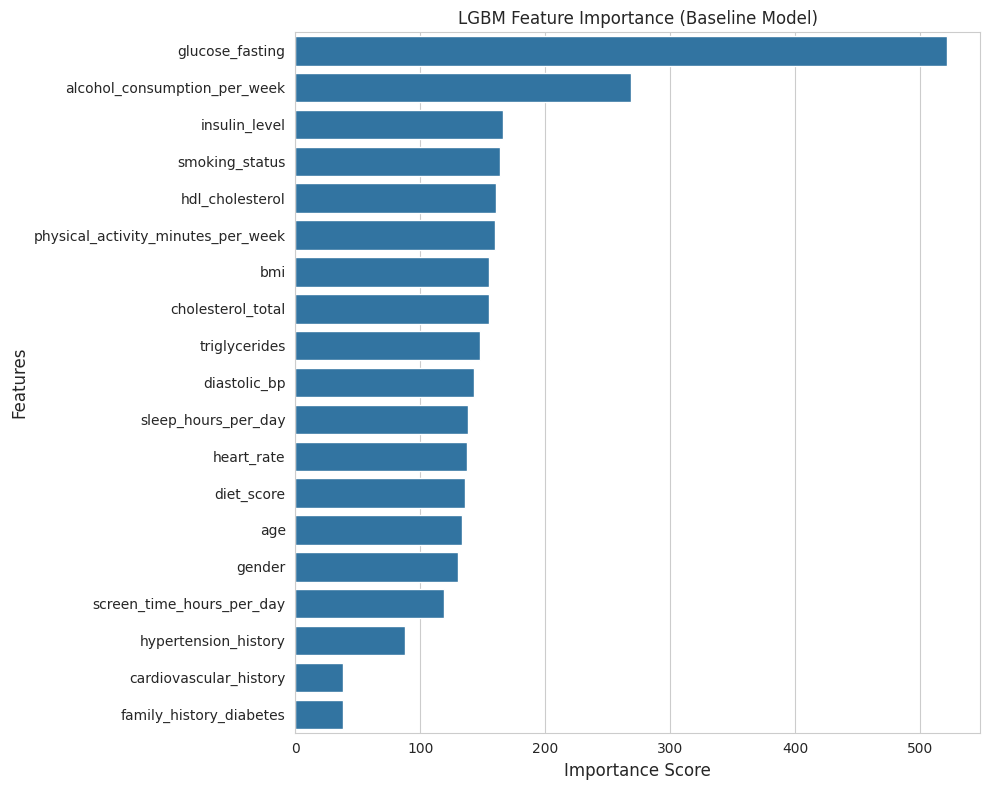

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extract the LGBMClassifier from the baseline_model pipeline
lgbm_classifier = baseline_model.named_steps['classifier']

# Get feature importances
feature_importances = lgbm_classifier.feature_importances_

# Get feature names after preprocessing
# This assumes 'preprocessor' was fitted and 'X_train' is available
feature_names_processed = preprocessor.get_feature_names_out()

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names_processed,
    'Importance': feature_importances
})

# Sort by importance
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Plotting the feature importances
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('LGBM Feature Importance (Baseline Model)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


### Preprocessing Simulation

In [18]:
# --- EKSEKUSI TRANSFORMASI DATA ---
# Mendapatkan nama fitur untuk rekonstruksi DataFrame
X_train_transformed = preprocessor.fit_transform(X_train)
feature_names = preprocessor.get_feature_names_out()

# Konversi kembali ke DataFrame untuk visualisasi di Bab 4
X_train_df = pd.DataFrame(X_train_transformed, columns=feature_names)

print("=== TABEL 4.1: PRATINJAU DATA SETELAH TRANSFORMASI (HEAD) ===")
display(X_train_df.head(10))
print("\n=== TABEL 4.1: PRATINJAU DATA SETELAH TRANSFORMASI (TAIL) ===")
display(X_train_df.tail(10))

# --- EKSEKUSI PENYEIMBANGAN DATA ---
# Menghitung proporsi sebelum resampling
before_resampling = y_train.value_counts().sort_index()

# Proses Resampling
X_resampled, y_resampled = resampler.fit_resample(X_train_transformed, y_train)

# Menghitung proporsi sesudah resampling
after_resampling = pd.Series(y_resampled).value_counts().sort_index()

# --- OUTPUT TABEL PROPORSI UNTUK BAB 4 ---
resampling_report = pd.DataFrame({
    'Kelas': ['0 (Non-Diabetes)', '1 (Diabetes)'],
    'Sebelum Resampling': before_resampling.values,
    'Sesudah Resampling': after_resampling.values,
    'Selisih': after_resampling.values - before_resampling.values
})

print("\n=== TABEL 4.2: PERBANDINGAN PROPORSI KELAS DATA LATIH ===")
display(resampling_report)

# --- EXTRACT ENCODER MAP FOR CATEGORICAL FEATURES ---
print("\n=== Ordinal Encoder Maps for Categorical Features ===")
# Access the ordinal encoder from the preprocessor
ordinal_encoder = preprocessor.named_transformers_['cat']

# Get the feature names the encoder was fitted on
encoder_feature_names = preprocessor.named_transformers_['cat'].feature_names_in_

# Iterate through categories and feature names to display the map
for i, feature_name in enumerate(encoder_feature_names):
    if feature_name in ['gender', 'smoking_status']:
        print(f"\nEncoder Map for '{feature_name}':")
        # Create a dictionary for better display
        category_map = {category: idx for idx, category in enumerate(ordinal_encoder.categories_[i])}
        display(pd.DataFrame(category_map.items(), columns=['Category', 'Encoded Value']))

=== TABEL 4.1: PRATINJAU DATA SETELAH TRANSFORMASI (HEAD) ===


,gender,smoking_status,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,triglycerides,glucose_fasting,insulin_level
0,1.0,1.0,59.0,2.0,56.0,3.7,6.7,4.2,0.0,0.0,1.0,24.8,80.0,71.0,145.0,39.0,178.0,112.0,7.35
1,0.0,2.0,46.0,4.0,254.0,7.1,7.5,5.5,1.0,0.0,0.0,24.8,73.0,59.0,214.0,66.0,116.0,133.0,13.64
2,1.0,2.0,63.0,2.0,25.0,4.1,8.8,10.3,0.0,0.0,0.0,22.1,65.0,67.0,139.0,47.0,135.0,128.0,2.00
3,0.0,2.0,86.0,3.0,39.0,4.4,6.8,4.0,0.0,0.0,0.0,23.1,80.0,73.0,212.0,63.0,102.0,108.0,2.00
4,0.0,2.0,60.0,0.0,157.0,6.4,8.3,6.2,0.0,1.0,0.0,25.1,91.0,79.0,208.0,53.0,97.0,114.0,5.68
5,0.0,2.0,88.0,0.0,86.0,3.1,8.4,6.2,0.0,1.0,0.0,26.0,83.0,71.0,198.0,61.0,30.0,122.0,7.37
6,0.0,1.0,55.0,1.0,56.0,5.1,6.1,3.4,0.0,0.0,0.0,29.4,81.0,57.0,164.0,35.0,78.0,104.0,11.87
7,1.0,2.0,38.0,6.0,6.0,5.7,7.2,8.7,0.0,1.0,0.0,23.2,79.0,64.0,170.0,54.0,76.0,101.0,2.00
8,1.0,2.0,50.0,1.0,22.0,2.2,7.5,9.9,0.0,0.0,0.0,36.7,74.0,70.0,187.0,68.0,114.0,128.0,21.15
9,0.0,0.0,53.0,1.0,14.0,5.3,8.6,5.8,1.0,0.0,1.0,22.4,81.0,88.0,200.0,63.0,143.0,117.0,8.52



=== TABEL 4.1: PRATINJAU DATA SETELAH TRANSFORMASI (TAIL) ===


,gender,smoking_status,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,sleep_hours_per_day,screen_time_hours_per_day,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,diastolic_bp,heart_rate,cholesterol_total,hdl_cholesterol,triglycerides,glucose_fasting,insulin_level
54194,0.0,0.0,64.0,3.0,51.0,5.8,5.5,3.4,0.0,0.0,0.0,26.7,88.0,82.0,189.0,61.0,161.0,115.0,8.95
54195,1.0,2.0,46.0,0.0,120.0,7.0,7.0,8.4,1.0,0.0,0.0,21.2,70.0,66.0,204.0,58.0,109.0,124.0,14.50
54196,1.0,0.0,52.0,2.0,46.0,4.1,6.7,3.9,1.0,0.0,0.0,30.9,69.0,87.0,239.0,41.0,95.0,142.0,16.17
54197,1.0,1.0,63.0,4.0,105.0,7.4,6.0,5.2,1.0,1.0,0.0,32.4,78.0,84.0,192.0,46.0,102.0,118.0,12.64
54198,0.0,2.0,68.0,0.0,75.0,2.0,6.4,1.9,0.0,0.0,0.0,31.0,81.0,57.0,200.0,35.0,105.0,131.0,9.89
54199,0.0,2.0,53.0,1.0,71.0,5.2,5.9,7.4,0.0,0.0,0.0,26.9,86.0,53.0,233.0,74.0,83.0,122.0,5.70
54200,1.0,0.0,89.0,3.0,87.0,6.6,6.0,5.2,1.0,0.0,0.0,28.1,79.0,80.0,225.0,58.0,108.0,140.0,9.01
54201,0.0,2.0,44.0,2.0,83.0,3.4,5.9,5.2,1.0,0.0,0.0,27.7,78.0,70.0,174.0,53.0,136.0,141.0,11.66
54202,0.0,1.0,53.0,3.0,85.0,7.0,5.0,7.7,0.0,0.0,0.0,25.5,74.0,72.0,129.0,68.0,102.0,103.0,11.61
54203,1.0,2.0,66.0,0.0,105.0,4.1,7.5,7.6,0.0,1.0,0.0,20.3,65.0,83.0,231.0,57.0,107.0,111.0,2.00



=== TABEL 4.2: PERBANDINGAN PROPORSI KELAS DATA LATIH ===


,Kelas,Sebelum Resampling,Sesudah Resampling,Selisih
0,0 (Non-Diabetes),6385,47808,41423
1,1 (Diabetes),47819,47808,-11



=== Ordinal Encoder Maps for Categorical Features ===

Encoder Map for 'gender':


,Category,Encoded Value
0,Female,0
1,Male,1
2,Other,2



Encoder Map for 'smoking_status':


,Category,Encoded Value
0,Current,0
1,Former,1
2,Never,2


## Evaluasi Hasil

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)

def evaluate_model_performance(model, X_train, y_train, X_test, y_test, model_name="Model"):
    """
    Fungsi evaluasi komprehensif untuk klasifikasi biner.
    Menampilkan tabel perbandingan metrik, Confusion Matrix, ROC Curve, dan PR Curve.
    """

    print(f"\n{'='*60}")
    print(f"EVALUATION REPORT: {model_name}")
    print(f"{'='*60}")

    # --- 1. PREDICTIONS ---
    y_train_pred = model.predict(X_train)
    y_train_proba = model.predict_proba(X_train)[:, 1]

    y_test_pred = model.predict(X_test)
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # --- 2. METRICS CALCULATION ---
    def calc_metrics(y_true, y_pred, y_proba):
        return {
            'Accuracy': accuracy_score(y_true, y_pred),
            'Precision': precision_score(y_true, y_pred),
            'Recall': recall_score(y_true, y_pred),
            'F1 Score': f1_score(y_true, y_pred),
            'ROC-AUC': roc_auc_score(y_true, y_proba),
            'PR-AUC': average_precision_score(y_true, y_proba)
        }

    train_metrics = calc_metrics(y_train, y_train_pred, y_train_proba)
    test_metrics = calc_metrics(y_test, y_test_pred, y_test_proba)

    # --- 3. PRINT COMPARISON TABLE ---
    df_compare = pd.DataFrame([train_metrics, test_metrics], index=['Training', 'Testing'])
    print("\n>>> Performance Comparison (Check for Overfitting):")
    print(df_compare.round(4))

    train_report = classification_report(y_train, y_train_pred, output_dict=True)
    test_report = classification_report(y_test, y_test_pred, output_dict=True)

    print("\n>>> Detailed Classification Report (Training Set):")
    display(pd.DataFrame(train_report).T)

    print("\n>>> Detailed Classification Report (Test Set):")
    display(pd.DataFrame(test_report).T)

    # --- 4. VISUALIZATION (Confusion Matrix only) ---

    # Create a single figure for both confusion matrices
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Plot A_train: Confusion Matrix (Training)
    cm_train = confusion_matrix(y_train, y_train_pred)
    sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
                xticklabels=['Non-T2DM', 'T2DM'],
                yticklabels=['Non-T2DM', 'T2DM'])
    axes[0].set_title(f"Confusion Matrix (Training) - {model_name}", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    # Plot A_test: Confusion Matrix (Testing)
    cm_test = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
                xticklabels=['Non-T2DM', 'T2DM'],
                yticklabels=['Non-T2DM', 'T2DM'])
    axes[1].set_title(f"Confusion Matrix (Test) - {model_name}", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Predicted")
    axes[1].set_ylabel("Actual")

    print(f"\n>>> Confusion Matrices (Training and Testing):")
    plt.tight_layout()
    plt.show()


    # --- 5. RETURN TEST METRICS ---
    test_metrics['Model'] = model_name
    return {
        'df_compare': df_compare,
        'train_classification_report': train_report,
        'test_classification_report': test_report,
        'cm_train': cm_train,
        'cm_test': cm_test
    }


EVALUATION REPORT: Baseline

>>> Performance Comparison (Check for Overfitting):
          Accuracy  Precision  Recall  F1 Score  ROC-AUC  PR-AUC
Training    0.9550     0.9940  0.9547    0.9740   0.9874  0.9984
Testing     0.9329     0.9808  0.9424    0.9612   0.9715  0.9964

>>> Detailed Classification Report (Training Set):


,precision,recall,f1-score,support
0,0.738311,0.957087,0.833583,6385.000000
1,0.994034,0.954704,0.973972,47819.000000
accuracy,0.954985,0.954985,0.954985,0.954985
macro avg,0.866172,0.955896,0.903778,54204.000000
weighted avg,0.963911,0.954985,0.957435,54204.000000



>>> Detailed Classification Report (Test Set):


,precision,recall,f1-score,support
0,0.666344,0.862155,0.751707,1596.00000
1,0.980846,0.942367,0.961222,11955.00000
accuracy,0.932920,0.932920,0.932920,0.93292
macro avg,0.823595,0.902261,0.856464,13551.00000
weighted avg,0.943805,0.932920,0.936546,13551.00000



>>> Confusion Matrices (Training and Testing):


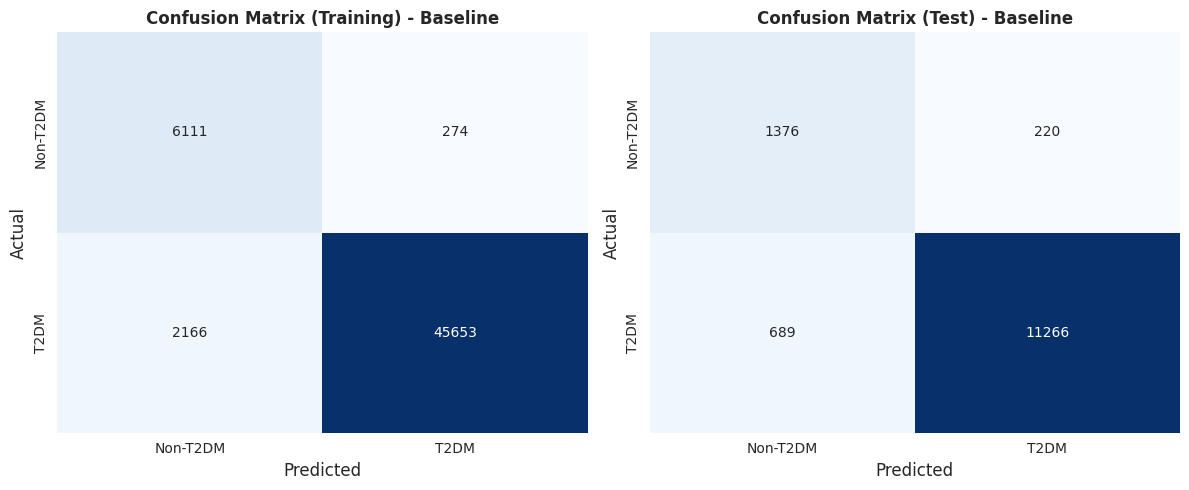

In [20]:
# Evaluate Baseline model and store the result in baseline_df_eval
evaluation_results = evaluate_model_performance(baseline_pipeline, X_train, y_train, X_test, y_test, "Baseline")
baseline_df_eval = evaluation_results['df_compare']
baseline_train_report = evaluation_results['train_classification_report']
baseline_test_report = evaluation_results['test_classification_report']
baseline_cm_train = evaluation_results['cm_train'] # Capture cm_train
baseline_cm_test = evaluation_results['cm_test']   # Capture cm_test

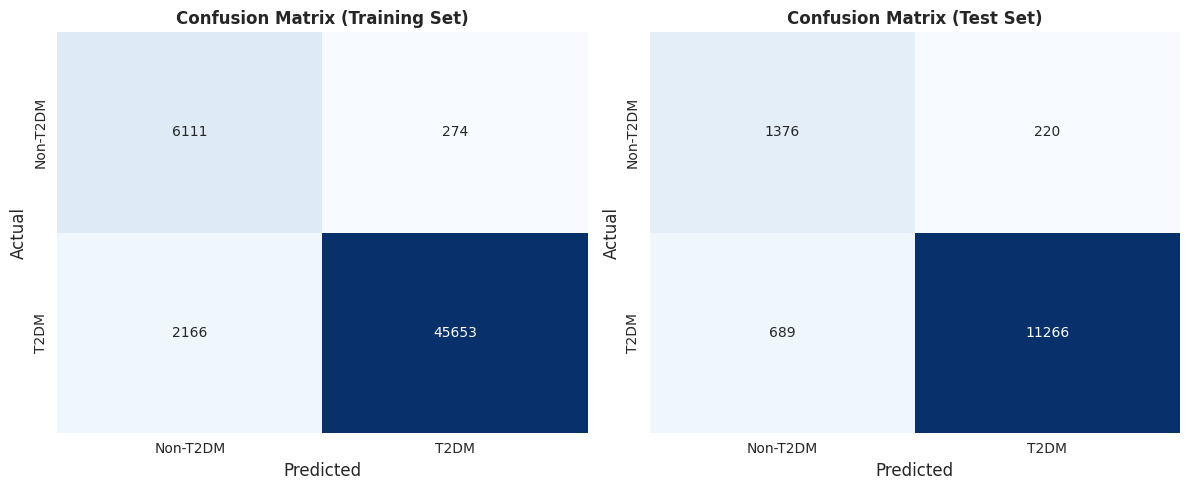

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# --- Predictions ---
y_train_pred = baseline_pipeline.predict(X_train)
y_test_pred = baseline_pipeline.predict(X_test)

# Create a single figure for both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Confusion Matrix (Training)
cm_train = confusion_matrix(y_train, y_train_pred)
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Non-T2DM', 'T2DM'],
            yticklabels=['Non-T2DM', 'T2DM'])
axes[0].set_title('Confusion Matrix (Training Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Plot Confusion Matrix (Test)
cm_test = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Non-T2DM', 'T2DM'],
            yticklabels=['Non-T2DM', 'T2DM'])
axes[1].set_title('Confusion Matrix (Test Set)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## SHAP


STARTING SHAP ANALYSIS FOR: BASELINE MODEL
>>> Transforming X_test for Baseline Model...
>>> Calculating SHAP values (TreeExplainer)...
>>> Calculation Complete. Generating Plots...

>>> Global Interpretation: BEESWARM PLOT


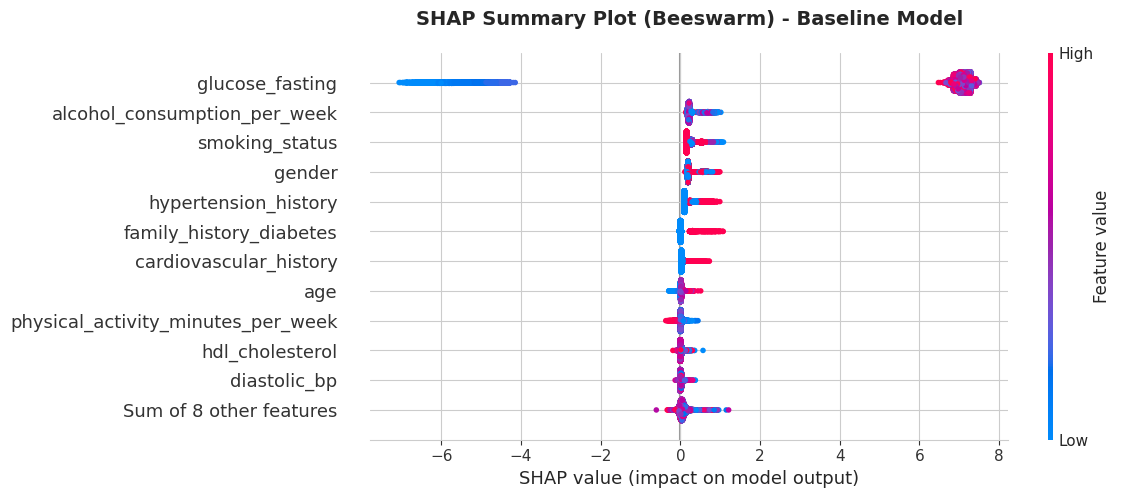


>>> Global Interpretation: BAR PLOT


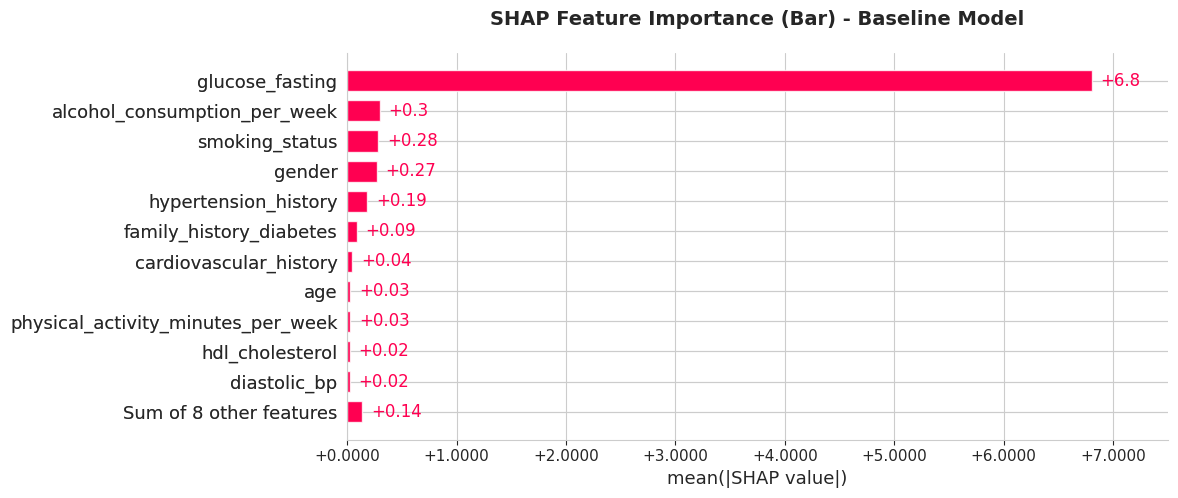


>>> Local Interpretation (Case Study) for Baseline Model: True Positive
    Sample Index (Test Set): 0 | Predicted: Positive | Actual: Positive


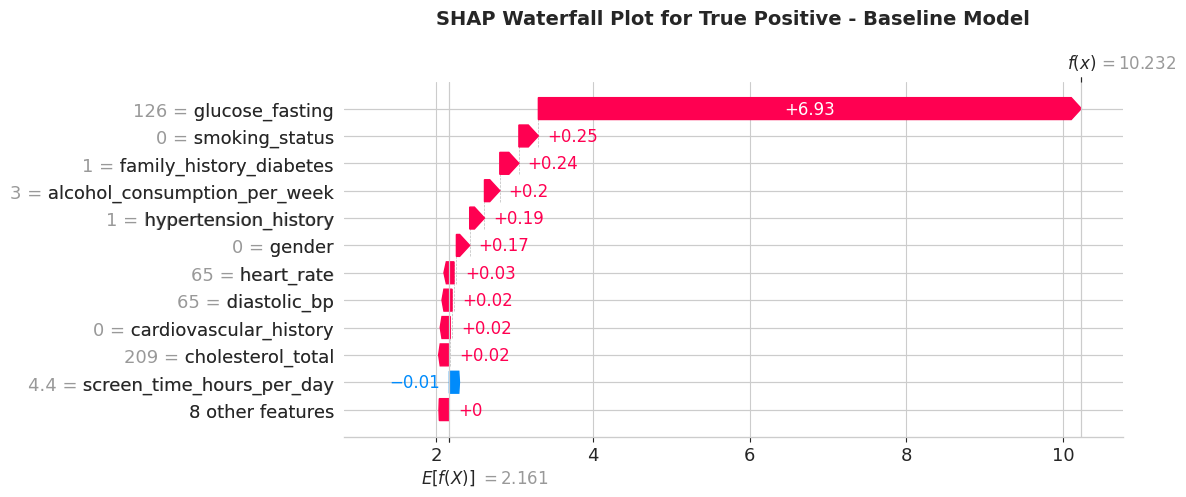


>>> Local Interpretation (Case Study) for Baseline Model: True Negative
    Sample Index (Test Set): 39 | Predicted: Negative | Actual: Negative


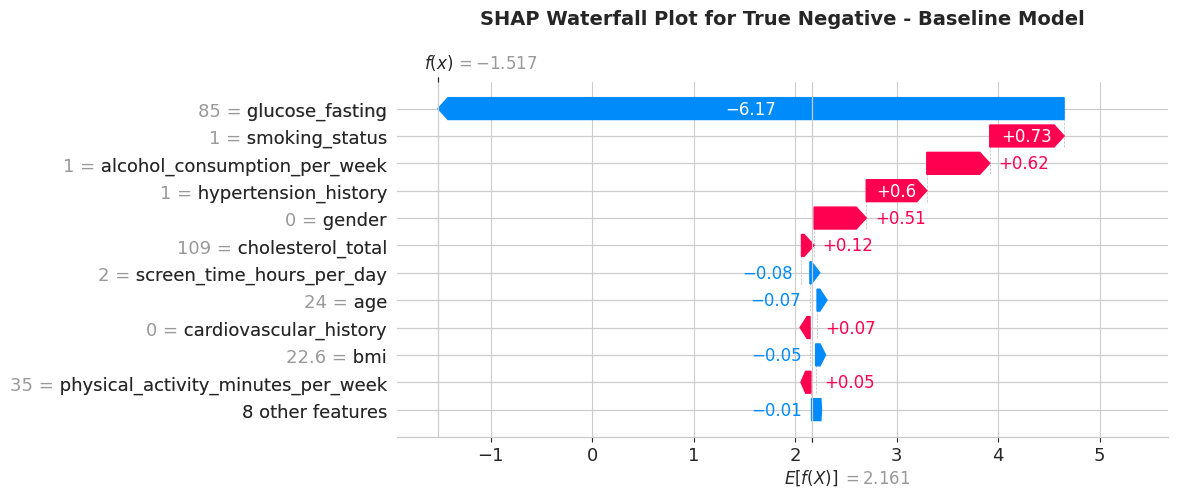

--------------------------------------------------------------------------------



In [25]:
import shap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.ticker import FuncFormatter

# Initialize JavaScript visualization for SHAP
shap.initjs()

# --- GLOBAL PLOT CONFIGURATION ---
FIG_SIZE = (12, 5.2)
TITLE_SIZE = 14
LABEL_SIZE = 14 # Changed from 10 to 14

plt.rcParams.update({
    'font.size': LABEL_SIZE,
    'axes.titlesize': TITLE_SIZE,
    'axes.labelsize': LABEL_SIZE
})

# --- CONFIGURATION (Sesuai Notebook Anda) ---
# Pastikan variabel best_optuna dan best_gridscv sudah terdefinisi di sel sebelumnya
models_to_evaluate = {
    'Baseline Model': baseline_pipeline,
    #'Optimized Model (GridSCV)': best_gridscv,
    #'Optimized Model (Optuna)': best_optuna,
}

# Container untuk menyimpan data hasil SHAP (Global & Local)
shap_export_data = {}

# --- ITERATIVE SHAP ANALYSIS ---
for model_name, pipeline in models_to_evaluate.items():
    print(f"\n{'='*80}")
    print(f"STARTING SHAP ANALYSIS FOR: {model_name.upper()}")
    print(f"{'='*80}")

    # 1. EXTRACT COMPONENTS
    try:
        classifier = pipeline.named_steps['classifier']
        preprocessor = pipeline.named_steps['preprocessor']
    except KeyError as e:
        print(f"Error: Could not extract steps from pipeline. Check step names. {e}")
        continue

    # 2. TRANSFORM TEST DATA
    print(f">>> Transforming X_test for {model_name}...")
    X_test_transformed_array = preprocessor.transform(X_test)
    feature_names = preprocessor.get_feature_names_out()
    X_test_transformed = pd.DataFrame(X_test_transformed_array, columns=feature_names, index=X_test.index)

    # 3. CALCULATE SHAP VALUES
    print(">>> Calculating SHAP values (TreeExplainer)...")
    explainer = shap.TreeExplainer(classifier)
    shap_values = explainer(X_test_transformed) # Menggunakan API explainer(...) baru yang lebih lengkap

    # Handle Binary Output (Focus on Positive Class / Class 1)
    # TreeExplainer pada LGBM binary biasanya return shape (N, Features).
    # Jika return (N, Features, 2), kita ambil index 1.
    if len(shap_values.shape) == 3:
        shap_values_target = shap_values[:, :, 1]
    else:
        shap_values_target = shap_values

    print(">>> Calculation Complete. Generating Plots...")

    # --- A. GLOBAL INTERPRETATION: BEESWARM PLOT ---
    print(f"\n>>> Global Interpretation: BEESWARM PLOT")
    plt.figure()
    shap.plots.beeswarm(shap_values_target, show=False, max_display=12)
    plt.gcf().set_size_inches(FIG_SIZE)
    plt.title(f"SHAP Summary Plot (Beeswarm) - {model_name}", fontsize=TITLE_SIZE, pad=20, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # --- B. GLOBAL INTERPRETATION: BAR PLOT ---
    print(f"\n>>> Global Interpretation: BAR PLOT")
    plt.figure()
    shap.plots.bar(shap_values_target, show=False, max_display=12) # Set max_display to show all features
    ax_bar = plt.gca()
    # Apply formatter to x-axis for bar plot values (assuming horizontal bars where values are on x)
    # Changed to format as two decimal places
    formatter = FuncFormatter(lambda x, p: f'{x:+.4f}') # Display as integer if whole number, else rounded to 0 decimal places
    ax_bar.xaxis.set_major_formatter(formatter)

    plt.gcf().set_size_inches(FIG_SIZE)
    plt.title(f"SHAP Feature Importance (Bar) - {model_name}", fontsize=TITLE_SIZE, pad=20, fontweight='bold')
    plt.tight_layout()
    plt.show()

    # --- C. LOCAL INTERPRETATION: WATERFALL PLOT ---
    y_pred = pipeline.predict(X_test)

    # Reset index agar matching dengan iloc
    y_test_reset = pd.Series(y_test).reset_index(drop=True)
    y_pred_reset = pd.Series(y_pred)

    local_data_tp = {}
    local_data_tn = {}

    # --- True Positive Case ---
    tp_sample_idx = None
    tp_indices = y_test_reset[(y_test_reset == 1) & (y_pred_reset == 1)].index.tolist()
    if tp_indices:
        tp_sample_idx = tp_indices[0]
        print(f"\n>>> Local Interpretation (Case Study) for {model_name}: True Positive")
        print(f"    Sample Index (Test Set): {tp_sample_idx} | Predicted: Positive | Actual: Positive")

        plt.figure()
        shap.plots.waterfall(shap_values_target[tp_sample_idx], show=False, max_display=12)
        plt.gcf().set_size_inches(FIG_SIZE)
        plt.title(f"SHAP Waterfall Plot for True Positive - {model_name}", fontsize=TITLE_SIZE, pad=20, fontweight='bold')
        plt.tight_layout()
        plt.show()

        local_data_tp = {
            "case_type": 'True Positive',
            "sample_index": int(tp_sample_idx),
            "base_value": round(float(shap_values_target[tp_sample_idx].base_values), 4),
            "prediction_value": round(float(shap_values_target[tp_sample_idx].values.sum() + shap_values_target[tp_sample_idx].base_values), 4),
            "feature_contributions": {k: round(v, 4) for k, v in zip(feature_names, shap_values_target[tp_sample_idx].values.tolist())}
        }
    else:
        print("\n>>> No True Positive samples found for local explanation.")
        local_data_tp = {"message": "No True Positive sample found."}

    # --- True Negative Case ---
    tn_sample_idx = None
    tn_indices = y_test_reset[(y_test_reset == 0) & (y_pred_reset == 0)].index.tolist()
    if tn_indices:
        tn_sample_idx = tn_indices[0]
        print(f"\n>>> Local Interpretation (Case Study) for {model_name}: True Negative")
        print(f"    Sample Index (Test Set): {tn_sample_idx} | Predicted: Negative | Actual: Negative")

        plt.figure()
        shap.plots.waterfall(shap_values_target[tn_sample_idx], show=False, max_display=12)
        plt.gcf().set_size_inches(FIG_SIZE)
        plt.title(f"SHAP Waterfall Plot for True Negative - {model_name}", fontsize=TITLE_SIZE, pad=20, fontweight='bold')
        plt.tight_layout()
        plt.show()

        local_data_tn = {
            "case_type": 'True Negative',
            "sample_index": int(tn_sample_idx),
            "base_value": round(float(shap_values_target[tn_sample_idx].base_values), 4),
            "prediction_value": round(float(shap_values_target[tn_sample_idx].values.sum() + shap_values_target[tn_sample_idx].base_values), 4),
            "feature_contributions": {k: round(v, 4) for k, v in zip(feature_names, shap_values_target[tn_sample_idx].values.tolist())}
        }
    else:
        print("\n>>> No True Negative samples found for local explanation.")
        local_data_tn = {"message": "No True Negative sample found."}

    print(f"{'-'*80}\n")

    # --- D. SAVE DATA FOR JSON EXPORT ---
    # Hitung Global Feature Importance (Mean Abs)
    global_imp_vals = np.abs(shap_values_target.values).mean(axis=0)
    global_imp_dict = dict(zip(feature_names, global_imp_vals))

    shap_export_data[model_name] = {
        "global_feature_importance": dict(sorted(global_imp_dict.items(), key=lambda x: x[1], reverse=True)),
        "local_explanation_true_positive": local_data_tp,
        "local_explanation_true_negative": local_data_tn,
        "raw_shap_values": shap_values_target.values.tolist() # Add raw SHAP values for beeswarm
    }

# Final Job


In [23]:
import json
import datetime
import numpy as np
from datetime import timezone, timedelta
from sklearn.metrics import confusion_matrix

# --- 1. Custom Encoder untuk menangani tipe data NumPy ---
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        elif isinstance(obj, np.floating):
            return float(obj)
        elif isinstance(obj, np.ndarray):
            return obj.tolist()
        elif isinstance(obj, datetime.datetime):
            # Ensure timezone-aware datetime objects are converted to ISO format
            if obj.tzinfo is not None and obj.tzinfo.utcoffset(obj) is not None:
                return obj.isoformat()
            else:
                # For naive datetime objects, assume local time and convert to string
                return obj.strftime("%Y-%m-%d %H:%M:%S")
        return super(NumpyEncoder, self).default(obj)

# --- 2. Helper untuk Ekstrak Params dari Model LGBM ---
def get_lgbm_params(pipeline):
    try:
        # Mencoba mengambil params langsung dari step classifier
        return pipeline.named_steps['classifier'].get_params()
    except:
        return "Could not extract params"

# --- Prepare metrics summary from baseline_df_eval ---
metrics_summary_list = []
detailed_reports_list = []

# Process Baseline Training results
metrics_summary_list.append({
    'Model': 'Baseline',
    'Set': 'Training',
    **baseline_df_eval.loc['Training'].to_dict(), # Unpack the Series as dict
    'elapsed_time_minutes': baseline_elapsed_time
})
detailed_reports_list.append({
    'Model': 'Baseline',
    'Set': 'Training',
    'report': baseline_train_report
})

# Process Baseline Testing results
metrics_summary_list.append({
    'Model': 'Baseline',
    'Set': 'Testing',
    **baseline_df_eval.loc['Testing'].to_dict(), # Unpack the Series as dict
    'elapsed_time_minutes': baseline_elapsed_time
})
detailed_reports_list.append({
    'Model': 'Baseline',
    'Set': 'Testing',
    'report': baseline_test_report
})

# --- Calculate Confusion Matrices ---
y_train_pred_export = baseline_pipeline.predict(X_train)
y_test_pred_export = baseline_pipeline.predict(X_test)

cm_train_export = confusion_matrix(y_train, y_train_pred_export).tolist()
cm_test_export = confusion_matrix(y_test, y_test_pred_export).tolist()

# --- 3. Kumpulkan Semua Informasi ---
# Define UTC+7 timezone
utc_plus_7 = timezone(timedelta(hours=7))

# Get current time in UTC+7
now_utc_plus_7 = datetime.datetime.now(utc_plus_7)

final_export_package = {
    "metadata": {
        "project_name": "Diabetes Prediction Analysis (Skripsi)",
        "exported_at": now_utc_plus_7, # Use timezone-aware datetime object
        "description": "Export of non-image data including raw features, metrics, best params, and SHAP values."
    },

    "data_info": {
        "raw_data_columns": data_raw.columns.tolist() if 'data_raw' in globals() else [],
        "features_used_for_training": X.columns.tolist() if 'X' in globals() else [],
        "target_column": label, # Adjusted to use 'label' variable
        "categorical_features_list": categorical_features if 'categorical_features' in globals() else [],
        "dataset_shape": {
            "total_rows": len(data_raw) if 'data_raw' in globals() else 0,
            "training_rows": len(X_train) if 'X_train' in globals() else 0,
            "testing_rows": len(X_test) if 'X_test' in globals() else 0
        },
        "resampling_report": resampling_report.to_dict(orient='records') if 'resampling_report' in globals() else []
    },

    "model_parameters": {
        "baseline_params": get_lgbm_params(baseline_pipeline),
        "gridscv_best_params": None, # Explicitly set to None as GridSCV was deleted
        "optuna_best_params": None   # Explicitly set to None as Optuna was deleted
    },

    "experiment_results": {
        "metrics_summary": metrics_summary_list,
        "model_evaluation_details": detailed_reports_list,
        "cross_validation_results": cv_results_df.to_dict(orient='records') if 'cv_results_df' in globals() else [],
        "confusion_matrices": {
            "training": cm_train_export,
            "testing": cm_test_export
        }
    },

    "interpretability_shap": shap_export_data # Variabel dari sel sebelumnya
}

# --- 4. Tulis ke File JSON dengan Timestamp ---
timestamp_str = now_utc_plus_7.strftime('%Y%m%d_%H%M%S') # Format timezone-aware datetime
filename = f"experiment_export_{timestamp_str}.json"

try:
    with open(filename, 'w') as f:
        json.dump(final_export_package, f, cls=NumpyEncoder, indent=4)
    print(f"\nSUCCESS! Data exported to: {filename}")

    # Auto-download jika di Google Colab
    try:
        from google.colab import files
        files.download(filename)
    except ImportError:
        pass

except Exception as e:
    print(f"Error exporting data: {e}")


SUCCESS! Data exported to: experiment_export_20260225_084236.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>